# Notebook 3 — Memory, Tools, and Agents

So far the model has answered one request at a time, using only what we put in the prompt.
This notebook adds the three things that turn a model into a useful assistant:

- **Memory:** the assistant remembers the conversation.
- **Tools:** the assistant can ask your code to look things up or do exact work.
- **Agents:** the assistant decides by itself which tools to use, step by step.

**What you will learn**

1. Why the model forgets, and how to keep the conversation.
2. Three memory strategies: full history, trimmed history, and a summary.
3. How to define tools and how one tool call works.
4. How to build an agent with `create_agent`.
5. How to give an agent memory.
6. How to keep tools and agents safe.

**Before you start**

```bash
ollama pull gpt-oss:20b
uv sync
```

Then choose the `.venv` Python kernel for this notebook. ⏱️ About 45 minutes.

## 1. Setup

In [1]:
import ast
import json
import operator
from pathlib import Path

import matplotlib.pyplot as plt
from langchain.agents import create_agent
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, trim_messages
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.tools import tool
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.errors import GraphRecursionError

from roadmap import get_chat_model

llm = get_chat_model()
print("Chat model:", llm.model)

ASSETS = Path("assets")
ASSETS.mkdir(exist_ok=True)

Chat model: gpt-oss:20b


## 2. The model forgets

A model has no memory of its own. Every call starts from zero, so the **app** must keep the
conversation and send it again with each new question. That kept conversation is what we call
**memory**.

Here is the simplest chat loop with memory: a Python list of messages.

In [2]:
SYSTEM = SystemMessage(content="You are a friendly assistant. Answer in at most two sentences.")
history = []


def chat(user_text: str) -> str:
    history.append(HumanMessage(content=user_text))
    response = llm.invoke([SYSTEM, *history])
    history.append(AIMessage(content=response.content))
    return response.content


print(chat("Hi! My name is Ada and I live in Lisbon."))
print(chat("What is my name?"))

Hi Ada! It’s great to meet someone from Lisbon—hope you’re enjoying the sunny streets and delicious pastéis de nata!


Your name is Ada.


The second answer works because the first exchange was sent again. Without the history, the
model has no idea:

In [3]:
print(llm.invoke([SYSTEM, HumanMessage(content="What is my name?")]).content)

I’m not sure what your name is—could you let me know?


## 3. Three memory strategies

![What do we send to the model on each turn?](assets/memory_strategies.svg)

Sending the full history works, but it grows with every turn. A longer prompt is slower, and
sooner or later it does not fit in the **context window**. There are three common strategies:

| Strategy | What is sent | Trade-off |
|---|---|---|
| Full history | every message | remembers all, but grows forever |
| Trimmed | only the last few messages | short, but forgets early facts |
| Summary | a summary of old messages + the last few | short and keeps key facts, but needs an extra model call |

Let's run the same seven-turn conversation with each strategy and measure the prompt size.
The name and city are only given in the **first** message, and the last question asks for
them.

In [4]:
TURNS = [
    "Hi! My name is Ada and I live in Lisbon.",
    "I want to start cooking at home. Any tips for a beginner?",
    "Suggest an easy breakfast.",
    "What about a quick lunch?",
    "And a simple dinner?",
    "Which of these three meals is the healthiest?",
    "What is my name, and which city do I live in?",
]


def full_history(history):
    return [SYSTEM, *history]


def trimmed_history(history):
    # Keep the last 4 messages. token_counter=len counts messages instead of tokens.
    recent = trim_messages(
        history, max_tokens=4, token_counter=len, strategy="last", start_on="human"
    )
    return [SYSTEM, *recent]


summary_chain = (
    ChatPromptTemplate.from_messages(
        [
            (
                "system",
                "Summarize the conversation so far in at most three short sentences. "
                "Call the person 'the user' and keep every fact the user shared about "
                "themselves, such as their name and city.",
            ),
            ("user", "{conversation}"),
        ]
    )
    | llm
    | StrOutputParser()
)


def summary_history(history):
    if len(history) <= 4:
        return [SYSTEM, *history]
    old_messages, recent = history[:-4], history[-4:]
    conversation = "\n".join(f"{m.type}: {m.content}" for m in old_messages)
    summary = summary_chain.invoke({"conversation": conversation})
    system = SystemMessage(
        content=f"{SYSTEM.content}\n\nSummary of the earlier part of this conversation: {summary}"
    )
    return [system, *recent]


def run_conversation(strategy):
    history, prompt_tokens = [], []
    for text in TURNS:
        history.append(HumanMessage(content=text))
        response = llm.invoke(strategy(history))
        prompt_tokens.append(response.usage_metadata["input_tokens"])
        history.append(AIMessage(content=response.content))
    return prompt_tokens, history[-1].content


results = {
    "full history": run_conversation(full_history),
    "trimmed": run_conversation(trimmed_history),
    "summary": run_conversation(summary_history),
}

for name, (_, last_answer) in results.items():
    print(f"{name:<13} last answer: {last_answer}")

full history  last answer: Your name is Ada, and you live in Lisbon.
trimmed       last answer: I don’t have that information, so I’m not sure what your name is or where you live.
summary       last answer: Your name is Ada, and you live in Lisbon.


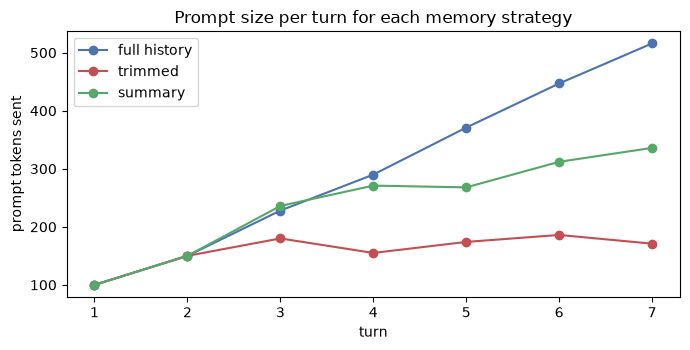

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
colors = {"full history": "#4C72B0", "trimmed": "#C44E52", "summary": "#55A868"}
for name, (tokens, _) in results.items():
    ax.plot(range(1, len(tokens) + 1), tokens, marker="o", label=name, color=colors[name])
ax.set_xlabel("turn")
ax.set_ylabel("prompt tokens sent")
ax.set_title("Prompt size per turn for each memory strategy")
ax.legend()
fig.tight_layout()
fig.savefig(ASSETS / "memory_tokens.png", dpi=120)
plt.show()

**What to notice**

- **Full history** grows on every turn, and it remembers the name and city.
- **Trimmed** stays small, but the first message was dropped, so it cannot answer the last
  question.
- **Summary** stays small *and* remembers, because the summary kept the key facts. The price is
  one extra model call per turn to write the summary. (Real apps update the summary step by
  step instead of rewriting it each time.)

> **A detail that matters.** Our first summary prompt produced "Ada from Lisbon greeted the
> AI...", and the model then said it did not know the user's name: it did not connect "Ada"
> with the person it was talking to. Asking the summary to say **"the user"** and putting it
> in the system message as "the earlier part of this conversation" fixed it. Small wording
> choices like this decide whether memory works.

## 4. Tools

A model can only write text. It cannot check today's order status, look into your database,
or do exact maths reliably. **Tools** fix this.

> **Tool:** a normal Python function that the model may *ask* you to run. The model sees the
> tool's **name**, its **description**, and its **arguments**, and uses them to decide when
> to call it.

The `@tool` decorator turns a function into a tool. The docstring becomes the description, so
write it for the model: say what the tool does and when to use it.

We build three tools for an online shop's support desk. The order data is made up.

In [6]:
ORDERS = {
    "4471": {
        "item": "Wireless headphones",
        "price": 59.90,
        "times_charged": 2,
        "status": "delivered 5 days ago",
    },
    "5120": {
        "item": "Coffee grinder",
        "price": 34.50,
        "times_charged": 1,
        "status": "in transit, arrives in 2 days",
    },
}


@tool
def lookup_order(order_id: str) -> str:
    """Look up an order by its number. Returns the item, price, how many times the customer
    was charged, and the delivery status."""
    order = ORDERS.get(order_id.strip().lstrip("#"))
    return json.dumps(order) if order else f"No order found with number {order_id}."


@tool
def get_return_policy() -> str:
    """Get the shop's rules for returns, refunds, and duplicate charges."""
    return (
        "Items can be returned within 30 days after delivery for a full refund. "
        "Duplicate charges are refunded automatically within 3 business days."
    )

The third tool is a calculator. Using Python's `eval()` here would be dangerous: the model
(or a user who tricks the model) could run any code. So the tool reads the expression as a
syntax tree and only allows numbers and `+ - * /`.

In [7]:
OPERATORS = {
    ast.Add: operator.add,
    ast.Sub: operator.sub,
    ast.Mult: operator.mul,
    ast.Div: operator.truediv,
    ast.USub: operator.neg,
}


def _evaluate(node):
    if isinstance(node, ast.Constant) and isinstance(node.value, int | float):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in OPERATORS:
        return OPERATORS[type(node.op)](_evaluate(node.left), _evaluate(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in OPERATORS:
        return OPERATORS[type(node.op)](_evaluate(node.operand))
    raise ValueError("only numbers and + - * / ( ) are allowed")


@tool
def calculate(expression: str) -> str:
    """Calculate a maths expression with numbers and + - * / ( ). Example: (59.90 * 2) - 10"""
    try:
        return str(round(_evaluate(ast.parse(expression, mode="eval").body), 2))
    except (ValueError, SyntaxError, ZeroDivisionError) as error:
        return f"Error: {error}"


TOOLS = {t.name: t for t in [lookup_order, get_return_policy, calculate]}

for t in TOOLS.values():
    print(f"{t.name}\n  description: {t.description}\n  arguments:   {t.args}\n")

lookup_order
  description: Look up an order by its number. Returns the item, price, how many times the customer
    was charged, and the delivery status.
  arguments:   {'order_id': {'title': 'Order Id', 'type': 'string'}}

get_return_policy
  description: Get the shop's rules for returns, refunds, and duplicate charges.
  arguments:   {}

calculate
  description: Calculate a maths expression with numbers and + - * / ( ). Example: (59.90 * 2) - 10
  arguments:   {'expression': {'title': 'Expression', 'type': 'string'}}



You can run a tool yourself, just like a function:

In [8]:
print(lookup_order.invoke({"order_id": "4471"}))
print(calculate.invoke({"expression": "59.90 * 2"}))
print(calculate.invoke({"expression": "__import__('os').system('ls')"}))

{"item": "Wireless headphones", "price": 59.9, "times_charged": 2, "status": "delivered 5 days ago"}
119.8
Error: only numbers and + - * / ( ) are allowed


The last line shows the safety check at work: anything that is not plain maths is refused.

## 5. One tool call, step by step

![One tool-calling round](assets/tool_calling.svg)

`bind_tools()` gives the model the list of tools. When the model needs one, it does **not**
run it. It returns an `AIMessage` with a **tool call**: the tool name and the arguments.

In [9]:
model_with_tools = llm.bind_tools(list(TOOLS.values()))

question = HumanMessage(content="How much did order 5120 cost?")
ai_message = model_with_tools.invoke([question])

print("Text:      ", repr(ai_message.content))
print("Tool calls:", ai_message.tool_calls)

Text:       ''
Tool calls: [{'name': 'lookup_order', 'args': {'order_id': '5120'}, 'id': '6a66937a-a3c5-4043-b7cb-6267dc89c6f3', 'type': 'tool_call'}]


The text is empty and there is a tool call instead. Now **our code** runs the tool. Calling a
tool with the whole tool call returns a `ToolMessage` that is linked to that call by its id:

In [10]:
tool_messages = [TOOLS[call["name"]].invoke(call) for call in ai_message.tool_calls]

for message in tool_messages:
    print(type(message).__name__, "->", message.content)

ToolMessage -> {"item": "Coffee grinder", "price": 34.5, "times_charged": 1, "status": "in transit, arrives in 2 days"}


Finally we send everything back: the question, the model's tool call, and the tool result.
Now the model can answer:

In [11]:
final = model_with_tools.invoke([question, ai_message, *tool_messages])
print(final.content)

Order 5120 was for a **Coffee grinder** and the price was **$34.50**.


The model only asks for a tool when it needs one:

In [12]:
reply = model_with_tools.invoke("What is the capital of France?")
print("Tool calls:", reply.tool_calls)
print("Answer:    ", reply.content)

Tool calls: []
Answer:     The capital of France is Paris.


## 6. Agents

![An agent is a model in a loop with tools](assets/agent_loop.svg)

In the last section **we** decided to run the tool and to call the model again. An **agent**
does this loop by itself:

> **Agent:** a model that works in a loop. It thinks, calls a tool (act), reads the result
> (observe), and repeats until it can answer. This pattern is called **ReAct**
> (reason + act).

`create_agent()` builds this loop for you. Let's turn our tools into a support agent.

In [13]:
SUPPORT_PROMPT = (
    "You are a support agent for an online shop. Use the tools to look up orders, check the "
    "rules, and do any maths. Never guess order details. Answer in at most three sentences."
)
support_agent = create_agent(llm, tools=list(TOOLS.values()), system_prompt=SUPPORT_PROMPT)


def show_steps(messages):
    """Print what happened in an agent run, one step per line."""
    for message in messages:
        if message.type == "human":
            print(f"USER        {message.content}")
        elif message.type == "ai" and message.tool_calls:
            for call in message.tool_calls:
                print(f"TOOL CALL   {call['name']}({call['args']})")
        elif message.type == "tool":
            print(f"TOOL RESULT {message.content}")
        elif message.type == "ai":
            print(f"ANSWER      {message.content}")


result = support_agent.invoke(
    {
        "messages": [
            HumanMessage(
                content="I was charged twice for order 4471. How much did I pay in total, "
                "and will I get the extra money back?"
            )
        ]
    }
)
show_steps(result["messages"])

USER        I was charged twice for order 4471. How much did I pay in total, and will I get the extra money back?
TOOL CALL   lookup_order({'order_id': '4471'})
TOOL RESULT {"item": "Wireless headphones", "price": 59.9, "times_charged": 2, "status": "delivered 5 days ago"}
TOOL CALL   calculate({'expression': '59.9 * 2'})
TOOL RESULT 119.8
TOOL CALL   get_return_policy({})
TOOL RESULT Items can be returned within 30 days after delivery for a full refund. Duplicate charges are refunded automatically within 3 business days.
ANSWER      You were charged $119.80 in total (59.90 × 2). According to our policy, duplicate charges are refunded automatically, so you’ll receive the extra $59.90 back within three business days.


One question, several steps: the agent looked up the order, calculated the total, checked the
rules, and only then answered. We never told it which tools to use or in what order.

You can also **stream** an agent and watch each step as it happens. With
`stream_mode="updates"`, every update says which part ran: `model` or `tools`.

In [14]:
question = {"messages": [HumanMessage(content="Can I still return order 5120?")]}

for update in support_agent.stream(question, stream_mode="updates"):
    for part, data in update.items():
        message = data["messages"][-1]
        if message.type == "ai" and message.tool_calls:
            shown = ", ".join(call["name"] for call in message.tool_calls)
        else:
            shown = message.content
        print(f"[{part:<5}] {shown}")

[model] lookup_order
[tools] {"item": "Coffee grinder", "price": 34.5, "times_charged": 1, "status": "in transit, arrives in 2 days"}


[model] get_return_policy
[tools] Items can be returned within 30 days after delivery for a full refund. Duplicate charges are refunded automatically within 3 business days.


[model] Order 5120 is still in transit and will arrive in 2 days, so you have up to 30 days after delivery to return it for a full refund. If you were charged twice, the extra amount will be refunded automatically within 3 business days.


## 7. Agents with memory

The agent above forgets everything after each run. To give it memory, add a
**checkpointer**. It saves the conversation for each **thread** (one thread = one
conversation). `InMemorySaver` keeps threads in memory; real apps save them in a database.

In [15]:
memory_agent = create_agent(
    llm,
    tools=list(TOOLS.values()),
    system_prompt=SUPPORT_PROMPT,
    checkpointer=InMemorySaver(),
)


def ask(text: str, thread_id: str) -> str:
    config = {"configurable": {"thread_id": thread_id}}
    result = memory_agent.invoke({"messages": [HumanMessage(content=text)]}, config)
    return result["messages"][-1].content


print("customer-1:", ask("Hi, I'm Ada. What is the status of order 5120?", "customer-1"))
print("customer-1:", ask("How much did it cost?", "customer-1"))
print("customer-2:", ask("How much did it cost?", "customer-2"))

customer-1: Hi Ada, your order 5120 for the coffee grinder is currently in transit and should arrive in 2 days.


customer-1: It cost $34.50.


customer-2: I’m happy to help! Could you please provide the order number so I can look up the exact cost for you?


In thread `customer-1` the agent knows that "it" means order 5120. Thread `customer-2` is a
new conversation, so the agent has to ask.

> The checkpointer keeps the **full** history. For long conversations, LangChain has
> middleware such as `SummarizationMiddleware` that applies the summary strategy from
> section 3 for you.

## 8. Keeping tools and agents safe

An agent decides on its own which tools to run and with which arguments. Treat that like
input from a stranger:

| Rule | Why |
|---|---|
| Check every tool argument | The model can pass wrong or harmful values. |
| Never give a tool that runs any code or shell command | Older tutorials use a "Python REPL" tool; one bad call can delete files. |
| Limit the number of steps | A confused agent can loop forever. |
| Ask a person before actions that change things | Refunds, emails, and deletions should be approved (see `HumanInTheLoopMiddleware`). |

The step limit is set with `recursion_limit`. Each model call and each tool run counts as a
step. With a very small limit, the agent stops with an error instead of looping:

In [16]:
try:
    support_agent.invoke(
        {"messages": [HumanMessage(content="Compare orders 4471 and 5120 for me.")]},
        {"recursion_limit": 2},
    )
except GraphRecursionError:
    print("Stopped: the agent needed more than 2 steps.")

Stopped: the agent needed more than 2 steps.


## 9. Summary

| Idea | What it means | In code |
|---|---|---|
| Memory | The app sends the conversation again with each call | a list of messages |
| Trimmed memory | Send only the last messages | `trim_messages(...)` |
| Summary memory | Send a summary of old messages + the last ones | a summary chain |
| Tool | A Python function the model can ask you to run | `@tool` |
| Tool call | The model's request: tool name + arguments | `AIMessage.tool_calls` |
| Tool result | The answer from your code, sent back to the model | `ToolMessage` |
| Agent | A model in a think → act → observe loop | `create_agent(model, tools)` |
| Agent memory | Saved conversation per thread | `checkpointer=InMemorySaver()` |
| Step limit | Stop agents that loop too long | `{"recursion_limit": N}` |

This is the end of the Stage 1 notebooks. Next, build the Stage 1 project,
[Message Analyzer](message-analyzer/), or continue to Stage 2, where the model answers from
your own documents (RAG).